In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import glob

# Change these to wherever your files are.
DATA = "../results/S1_all_radii/metrics/*.csv"
METADATA = "../data/species_metadata.csv"

sns.set_context("talk")
pd.options.display.max_columns = None

In [23]:
csv_files = glob.glob(DATA)
species_metadata = pd.read_csv(METADATA)

full_df = pd.concat((pd.read_csv(f) for f in csv_files), ignore_index=True)
full_df = pd.merge(full_df, species_metadata, on=["species"])
full_df["movement"] = pd.Categorical(full_df["movement"], ['WALK', 'FLY', 'SWIM'])
full_df["downsample"] = full_df["downsample_rate_minutes"]
full_df["stop_radius_d"] = full_df["stop_radius_description"]
df = full_df[
    (full_df["days_spanned"] >= 60)
]



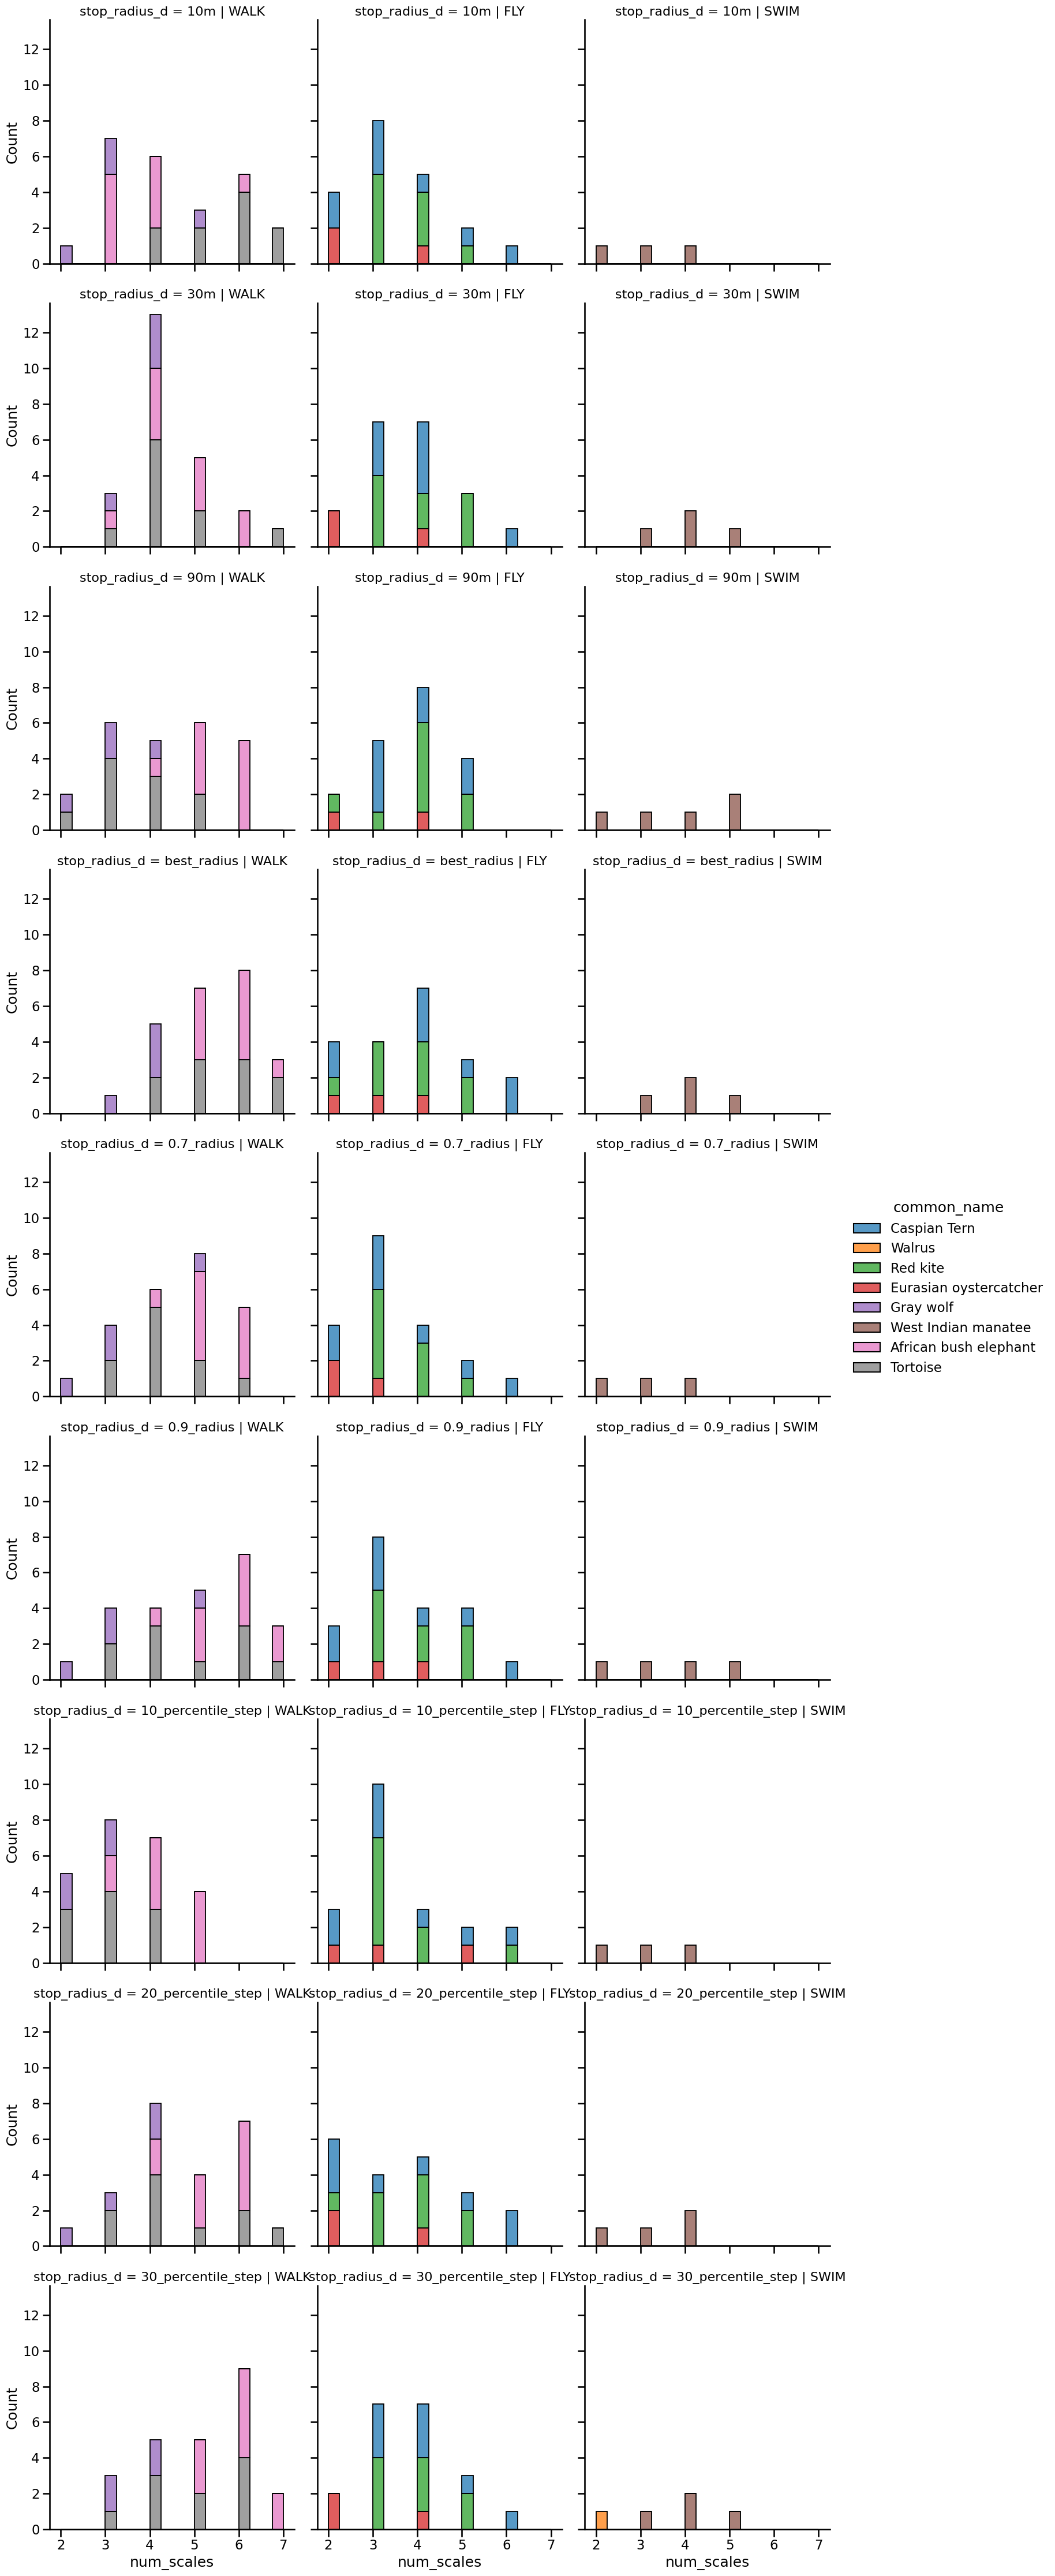

In [24]:
# for movement in ["WALK", "FLY", "SWIM"]:
_df = df[
    (df["downsample"] == 60) &
    (df["num_scales"] >= 2)]#df[df["movement"] == movement]

g = sns.displot(data=_df, row="stop_radius_d", x="num_scales", hue="common_name", col="movement", multiple="stack", bins=20)
g.set_titles(col_template="{col_name}", size=16)

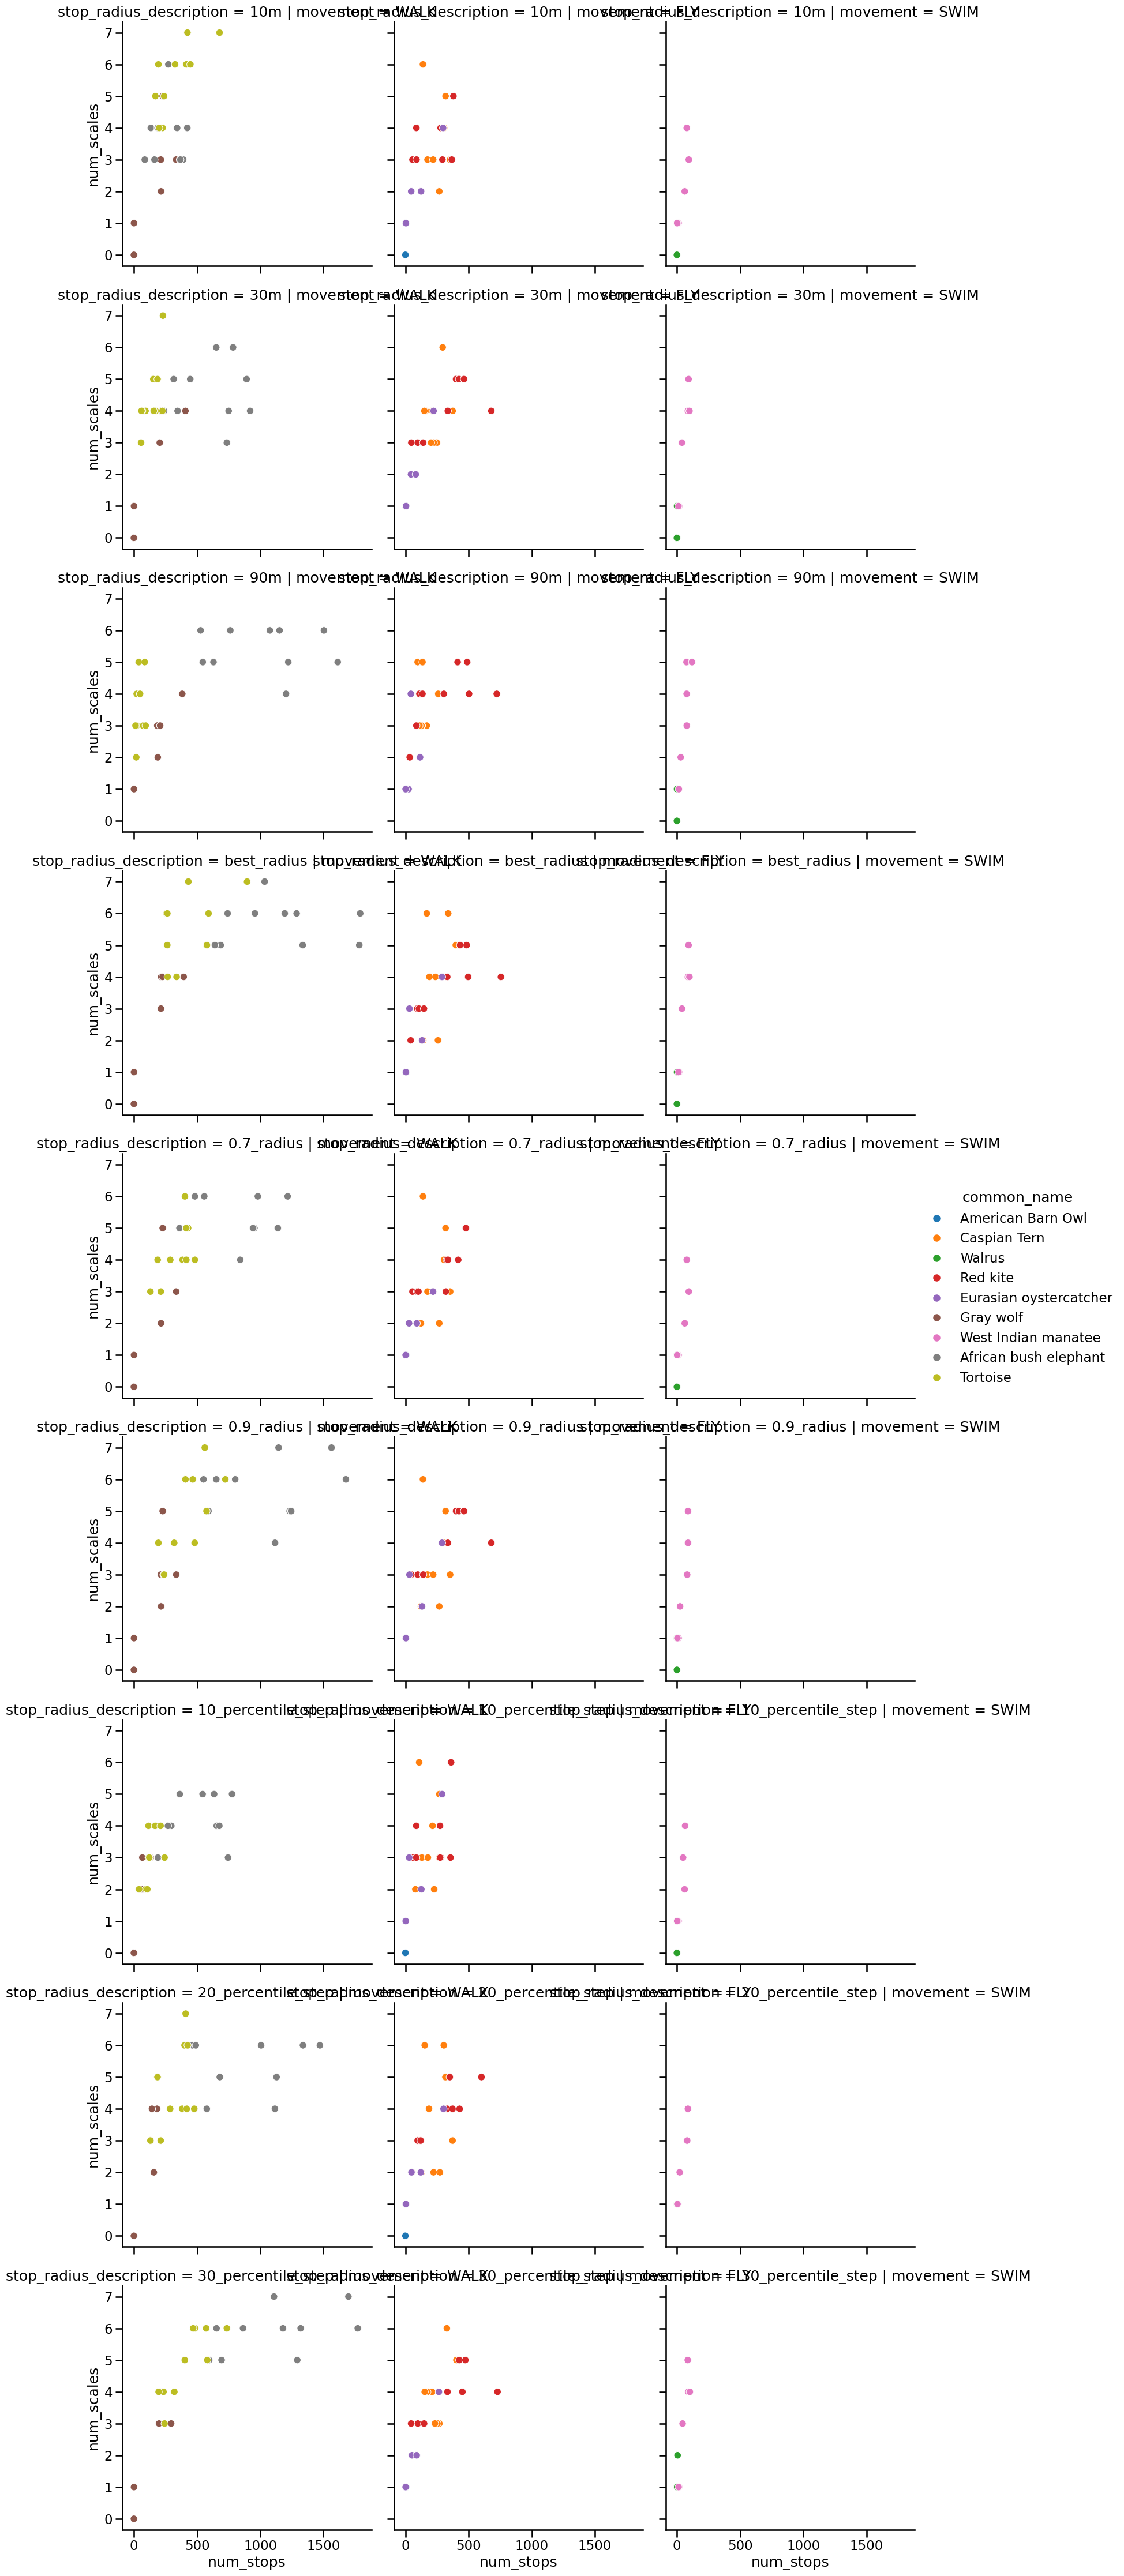

In [10]:
_df = df[
    (df["downsample"] == 60) &
    True
    ]
sns.relplot(data=_df, x="num_stops", y="num_scales", col="movement", hue="common_name", row="stop_radius_description")

313/384 animals


,num_scales
movement,
WALK,4.660714
FLY,3.830508
SWIM,3.888889


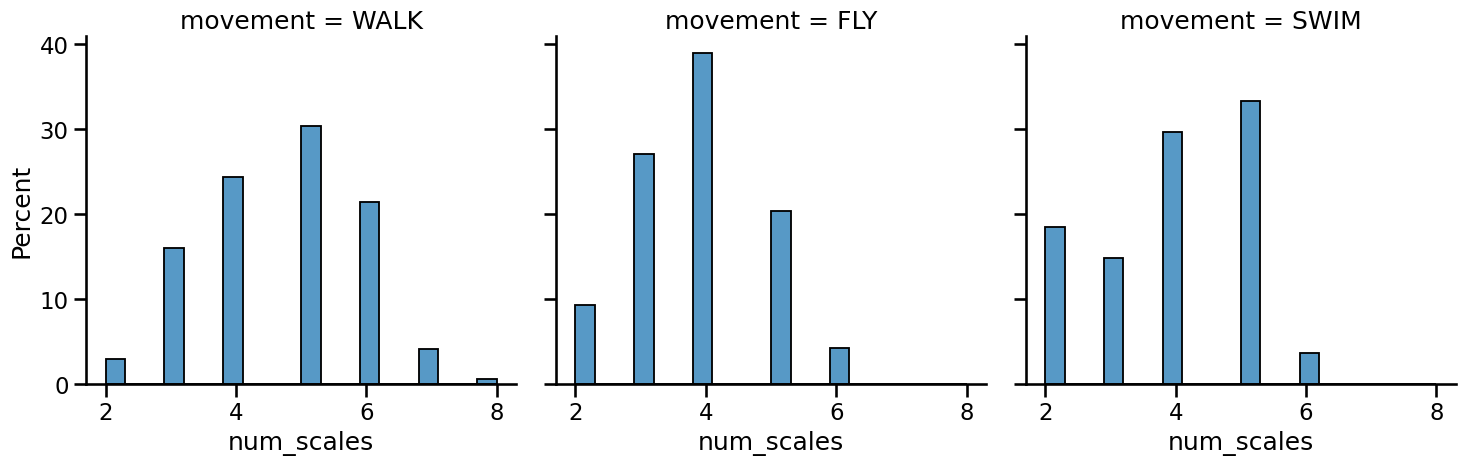

In [7]:
_df = df [
    # (df["median_minutes_between_gps"] <= 90) &
    (df["days_spanned"] >= 60) &
    (df["num_scales"] >= 2) &
    # (df["num_stops"] >= 10) &
    True
]
print(f"{len(_df)}/{len(df)} animals")
p = sns.displot(data=_df, x="num_scales", col="movement", stat="percent", common_norm=False, bins=20)
_df[["movement", "num_scales"]].groupby("movement", observed=True).mean("num_scales")

In [12]:
filtered = df[
    # (df["Stop Radius"] == 30) & 
    # (aggregated["Locomotion"] != "swim") &
    (df["days_spanned"] >= 60) &
    
    (df["num_scales"] >= 4) &
    (df["final_size_2"] <= 10000) & # weird outlier -- not sure which this is
    (df["median_speed"] <= 0.1) & # weird outlier -- arctic foxes
    (df["movement"] != "SWIM") &
    # (df["median_minutes_between_gps"] <= 70) &
    # (aggregated["Final Size 2"] >= 2000) & # weird outlier
    True
]

MOVEMENT_ORDER = ["WALK", "FLY"]
FAMILY_ORDER = filtered.family.unique()


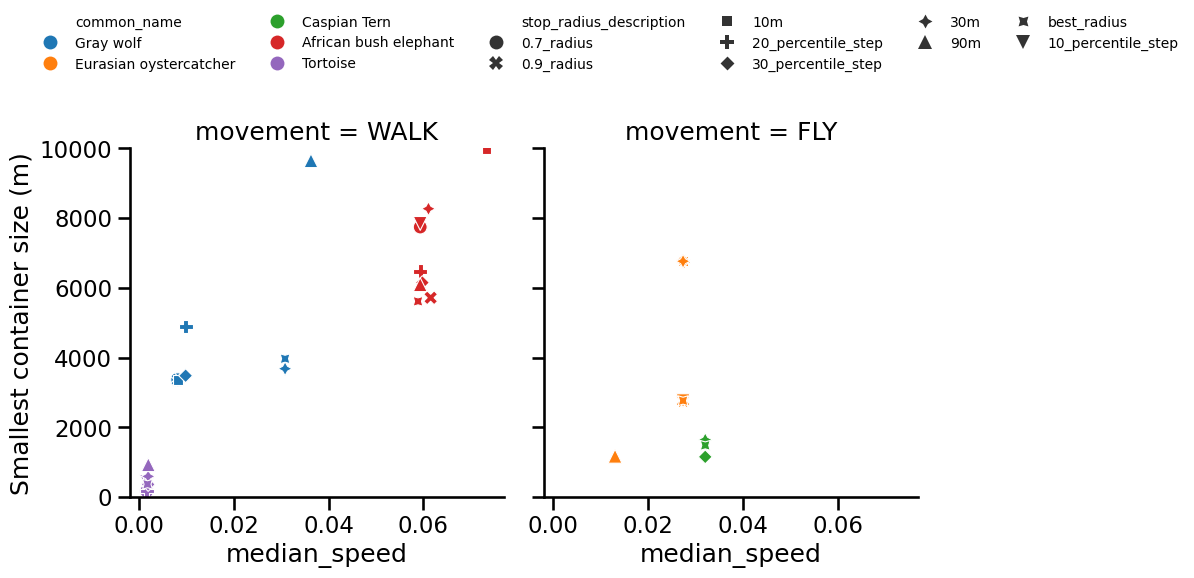

In [21]:
_aggregated = filtered.groupby(["species", "stop_radius_description"]).agg(
    {
        "movement": "first",
        "median_body_length_cm": "first",
        "stop_radius": "mean",
        "common_name": "first",
        "class": "first",
        "family": "first",
        "median_speed": "median",
        "num_scales": "mean",
        "final_size_2": "median",
    }
).reset_index()

p = sns.relplot(
    data=_aggregated,
    x="median_speed",
    y="final_size_2",
    hue="common_name",
    style="stop_radius_description",
    col="movement", s=100, legend=True,
    col_order=MOVEMENT_ORDER,
    # hue_order=FAMILY_ORDER,
    # size="stop_radius",
    # alpha=0.5
)

p.set(ylim=(0, 10000), ylabel="Smallest container size (m)")


sns.move_legend(
    p,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncols=6,
    title=None,
    frameon=False,
    fontsize=10,
)

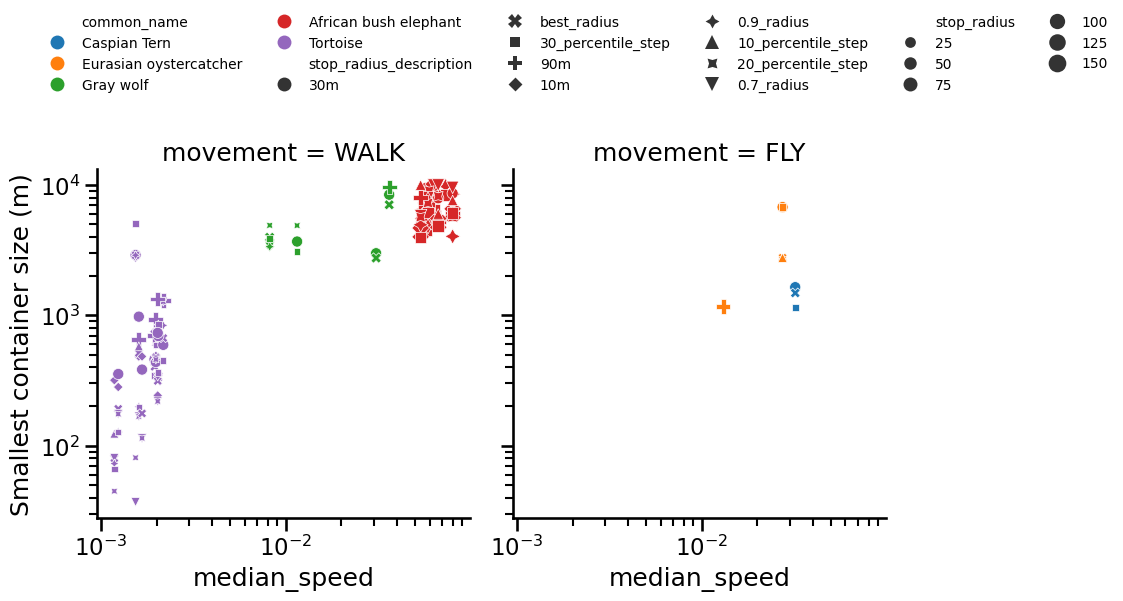

In [20]:
p = sns.relplot(
    data=filtered,
    x="median_speed",
    y="final_size_2",
    hue="common_name",
    style="stop_radius_description",
    col="movement", s=100, legend=True,
    col_order=MOVEMENT_ORDER,
    size="stop_radius",
    # hue_order=FAMILY_ORDER,
)
p.set(yscale="log", xscale="log", ylabel="Smallest container size (m)")


sns.move_legend(
    p,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncols=6,
    title=None,
    frameon=False,
    fontsize=10,
)


In [237]:
zoom_in = [
    "259966228", # african bush elephant, low temporal
    "190490326", # tortoise
    "1120749252", # geoffrey's spider monkey, high temporal
    "492444603", # gray wolf, high temporal
    "1426277950", # american barn owls (3)
    "501903109", # red kite
    "1605799506", # eurasian oystercatcher
    "1480583194", # caspian tern
    "1936932457", # manatee
    "1420256397", # walrus
]

In [234]:
_df = df_10[
    # (df_10["median_minutes_between_gps"] <= 30) &
    # (df_10["mean_minutes_between_gps"] <= 120) &
    (df_10["days_spanned"] >= 60) &
    (df_10["movement"] == "SWIM") 
]
# _df[_df["dataset"] == np.random.choice(_df[_df["movement"] == "FLY"]["dataset"].unique())]
_df["common_name"].unique()


array(['Walrus', 'West Indian manatee', 'California sea lion',
       'Northern elephant seal'], dtype=object)

In [236]:
_df[_df["common_name"] == ""]

,Unnamed: 0_x,dataset,species,individual,stop_radius,label_singleton,downsample_rate_minutes,median_minutes_between_gps,mean_minutes_between_gps,median_speed,mean_speed,num_gps_points,data_starts,data_ends,days_spanned,max_speed,num_stops,num_scales,final_sizes,final_size_2,final_size_3,final_size_4,Unnamed: 0_y,movement,fly_detail,class,order,family,genus,common_name,median_body_length_cm
10370,176,259966228,Mirounga angustirostris,seal 2004001,30,True,10,60.0,60.000000,0.614902,0.625148,1790,2004-02-23 01:45:00,2004-05-07 15:45:00,74.541667,1.463046,1,0,[],0.0,0.0,0.0,117,SWIM,NaN,Mammalia,Carnivora,Phocidae,Mirounga,Northern elephant seal,350.0
10372,178,259966228,Mirounga angustirostris,seal 2004003,30,True,10,60.0,60.000000,0.868020,0.839288,2017,2004-02-18 16:00:00,2004-05-12 17:00:00,84.000000,1.863625,1,0,[],0.0,0.0,0.0,117,SWIM,NaN,Mammalia,Carnivora,Phocidae,Mirounga,Northern elephant seal,350.0
10374,180,259966228,Mirounga angustirostris,seal 2004004,30,True,10,60.0,60.000000,1.027249,0.997541,2449,2004-02-21 20:20:00,2004-06-02 21:20:00,102.000000,1.936344,0,0,[],0.0,0.0,0.0,117,SWIM,NaN,Mammalia,Carnivora,Phocidae,Mirounga,Northern elephant seal,350.0
10376,182,259966228,Mirounga angustirostris,seal 2004005,30,True,10,60.0,60.000000,0.679497,0.634300,1937,2004-02-22 17:45:00,2004-05-13 10:45:00,80.666667,1.337538,0,0,[],0.0,0.0,0.0,117,SWIM,NaN,Mammalia,Carnivora,Phocidae,Mirounga,Northern elephant seal,350.0
10378,184,259966228,Mirounga angustirostris,seal 2004006,30,True,10,60.0,59.984717,0.773596,0.754990,1964,2004-02-25 21:45:00,2004-05-17 17:15:00,81.770833,1.792996,0,0,[],0.0,0.0,0.0,117,SWIM,NaN,Mammalia,Carnivora,Phocidae,Mirounga,Northern elephant seal,350.0
10380,186,259966228,Mirounga angustirostris,seal 2004017,30,True,10,60.0,60.000000,0.452929,0.476513,5485,2004-06-06 00:00:00,2005-01-20 11:00:00,228.500000,1.364339,5,0,{},0.0,0.0,0.0,117,SWIM,NaN,Mammalia,Carnivora,Phocidae,Mirounga,Northern elephant seal,350.0
10382,188,259966228,Mirounga angustirostris,seal 2004018,30,True,10,60.0,60.000000,0.523195,0.543163,5595,2004-05-28 17:45:00,2005-01-16 18:45:00,233.083333,1.182121,0,0,[],0.0,0.0,0.0,117,SWIM,NaN,Mammalia,Carnivora,Phocidae,Mirounga,Northern elephant seal,350.0
10384,190,259966228,Mirounga angustirostris,seal 2004021,30,True,10,60.0,60.000000,0.466440,0.484717,5427,2004-05-29 13:15:00,2005-01-10 14:15:00,226.083333,1.595354,0,0,[],0.0,0.0,0.0,117,SWIM,NaN,Mammalia,Carnivora,Phocidae,Mirounga,Northern elephant seal,350.0
10386,192,259966228,Mirounga angustirostris,seal 2004022,30,True,10,60.0,60.000000,0.325400,0.358311,5431,2004-05-29 12:30:00,2005-01-10 17:30:00,226.250000,1.343793,0,0,[],0.0,0.0,0.0,117,SWIM,NaN,Mammalia,Carnivora,Phocidae,Mirounga,Northern elephant seal,350.0
10388,194,259966228,Mirounga angustirostris,seal 2004025,30,True,10,60.0,60.000000,0.592404,0.599434,5358,2004-06-09 05:30:00,2005-01-18 09:30:00,223.208333,1.430620,3,0,{},0.0,0.0,0.0,117,SWIM,NaN,Mammalia,Carnivora,Phocidae,Mirounga,Northern elephant seal,350.0


In [61]:
full_df.species.unique()

array(['Tyto furcata', 'Hydroprogne caspia', 'Odobenus rosmarus',
       'Milvus milvus', 'Haematopus ostralegus', 'Canis lupus',
       'Trichechus manatus', 'Loxodonta africana', 'Testudinidae'],
      dtype=object)

In [67]:
full_df.groupby("species").agg(
    {"common_name": "first"})

,common_name
species,
Canis lupus,Gray wolf
Haematopus ostralegus,Eurasian oystercatcher
Hydroprogne caspia,Caspian Tern
Loxodonta africana,African bush elephant
Milvus milvus,Red kite
Odobenus rosmarus,Walrus
Testudinidae,Tortoise
Trichechus manatus,West Indian manatee
Tyto furcata,American Barn Owl
